In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [2]:
DATA_PATH = Path("../data/PS_20174392719_1491204439457_log.csv")

print("File exists:", DATA_PATH.exists())
print("File size (MB):", round(DATA_PATH.stat().st_size / (1024**2), 2)
      if DATA_PATH.exists() else "File not found")

File exists: True
File size (MB): 470.67


In [3]:
df = pd.read_csv(
    DATA_PATH,
    dtype={
        "step": "int32",
        "type": "category",
        "nameOrig": "string",
        "nameDest": "string",
        "isFraud": "int8",
        "isFlaggedFraud": "int8"
    }
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
df = df.drop(
    columns=[
        "orig_balance_error",
        "dest_balance_error"
    ],
    errors="ignore"
)

print(df.shape)
print(df.columns.tolist())

(6362620, 11)
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']


In [5]:
# Count transactions in each time step
step_counts = (
    df.groupby("step", observed=True)
      .size()
      .sort_index()
)

# Cumulative number of transactions
cumulative_counts = step_counts.cumsum()

total_transactions = len(df)

# Find the time-step boundaries closest to 60% and 80%
train_target = total_transactions * 0.60
validation_target = total_transactions * 0.80

train_end_step = (
    cumulative_counts - train_target
).abs().idxmin()

validation_end_step = (
    cumulative_counts - validation_target
).abs().idxmin()

print("Training ends at step:", train_end_step)
print("Validation ends at step:", validation_end_step)

Training ends at step: 281
Validation ends at step: 354


In [6]:
train_df = df[df["step"] <= train_end_step].copy()

val_df = df[
    (df["step"] > train_end_step) &
    (df["step"] <= validation_end_step)
].copy()

test_df = df[df["step"] > validation_end_step].copy()

In [7]:
datasets = {
    "Training": train_df,
    "Validation": val_df,
    "Testing": test_df
}

for name, data in datasets.items():
    print(f"\n{name}")
    print("Transactions:", len(data))
    print("Fraud cases:", data["isFraud"].sum())
    print("Fraud percentage:", round(data["isFraud"].mean() * 100, 4), "%")
    print("First step:", data["step"].min())
    print("Last step:", data["step"].max())


Training
Transactions: 3820599
Fraud cases: 3193
Fraud percentage: 0.0836 %
First step: 1
Last step: 281

Validation
Transactions: 1248498
Fraud cases: 762
Fraud percentage: 0.061 %
First step: 282
Last step: 354

Testing
Transactions: 1293523
Fraud cases: 4258
Fraud percentage: 0.3292 %
First step: 355
Last step: 743


In [8]:
train_steps = set(train_df["step"].unique())
val_steps = set(val_df["step"].unique())
test_steps = set(test_df["step"].unique())

print("Train / Validation overlap:", len(train_steps & val_steps))
print("Train / Test overlap:", len(train_steps & test_steps))
print("Validation / Test overlap:", len(val_steps & test_steps))

Train / Validation overlap: 0
Train / Test overlap: 0
Validation / Test overlap: 0


In [9]:
target = "isFraud"

excluded_columns = [
    "isFraud",
    "isFlaggedFraud",
    "nameOrig",
    "nameDest"
]

X_train = train_df.drop(columns=excluded_columns)
y_train = train_df[target]

X_val = val_df.drop(columns=excluded_columns)
y_val = val_df[target]

X_test = test_df.drop(columns=excluded_columns)
y_test = test_df[target]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (3820599, 7)
y_train: (3820599,)
X_val: (1248498, 7)
y_val: (1248498,)
X_test: (1293523, 7)
y_test: (1293523,)


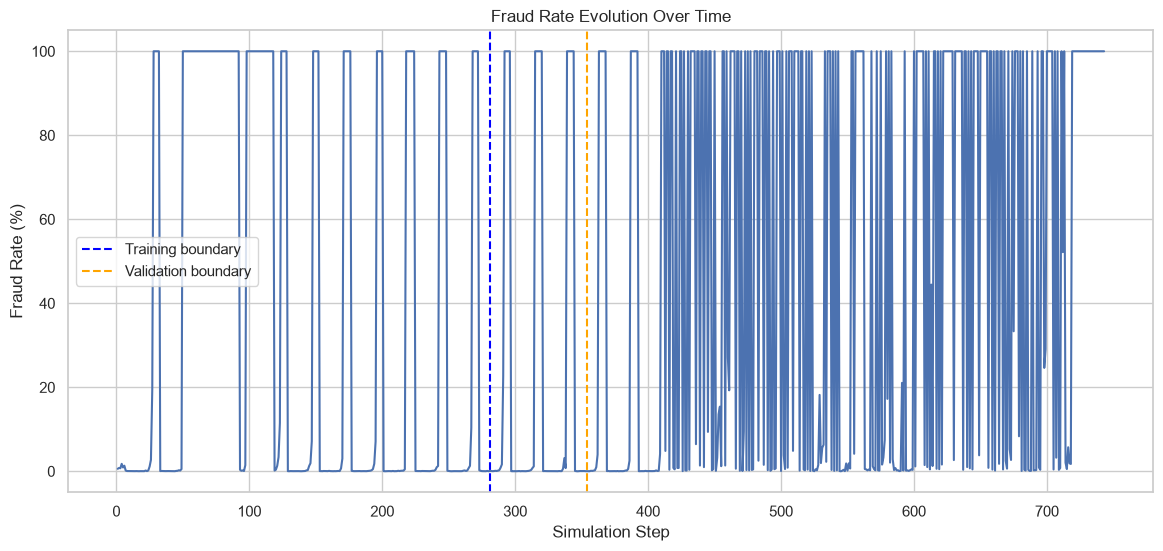

In [10]:
fraud_by_step = df.groupby("step").agg(
    total_transactions=("isFraud", "count"),
    fraud_transactions=("isFraud", "sum")
)

fraud_by_step["fraud_rate"] = (
    fraud_by_step["fraud_transactions"]
    / fraud_by_step["total_transactions"]
) * 100

plt.figure(figsize=(14, 6))

plt.plot(
    fraud_by_step.index,
    fraud_by_step["fraud_rate"]
)

plt.axvline(
    train_end_step,
    color="blue",
    linestyle="--",
    label="Training boundary"
)

plt.axvline(
    validation_end_step,
    color="orange",
    linestyle="--",
    label="Validation boundary"
)

plt.title("Fraud Rate Evolution Over Time")
plt.xlabel("Simulation Step")
plt.ylabel("Fraud Rate (%)")
plt.legend()
plt.show()

In [11]:
print("Categorical columns:")
print(X_train.select_dtypes(include=["category", "object"]).columns.tolist())

print("\nNumerical columns:")
print(X_train.select_dtypes(include=["number"]).columns.tolist())

print("\nTransaction types:")
print(X_train["type"].value_counts())

Categorical columns:
['type']

Numerical columns:
['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']

Transaction types:
type
CASH_OUT    1357358
PAYMENT     1287159
CASH_IN      837044
TRANSFER     315549
DEBIT         23489
Name: count, dtype: int64


In [12]:
# Aggregate transaction counts and fraud counts by step
fraud_by_step = (
    df.groupby("step")
      .agg(
          total_transactions=("isFraud", "count"),
          fraud_transactions=("isFraud", "sum")
      )
      .sort_index()
)

# Calculate rolling totals over 24 steps
fraud_by_step["rolling_transactions"] = (
    fraud_by_step["total_transactions"]
    .rolling(window=24, min_periods=24)
    .sum()
)

fraud_by_step["rolling_fraud"] = (
    fraud_by_step["fraud_transactions"]
    .rolling(window=24, min_periods=24)
    .sum()
)

# Calculate rolling fraud percentage
fraud_by_step["rolling_fraud_rate"] = (
    fraud_by_step["rolling_fraud"]
    / fraud_by_step["rolling_transactions"]
) * 100

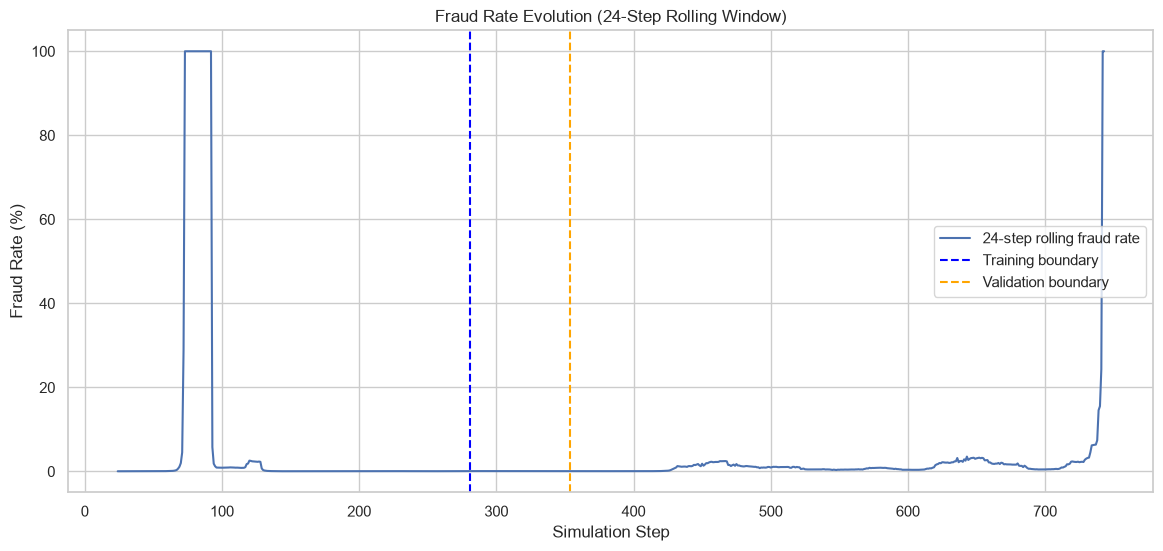

In [13]:
plt.figure(figsize=(14, 6))

plt.plot(
    fraud_by_step.index,
    fraud_by_step["rolling_fraud_rate"],
    label="24-step rolling fraud rate"
)

plt.axvline(
    train_end_step,
    color="blue",
    linestyle="--",
    label="Training boundary"
)

plt.axvline(
    validation_end_step,
    color="orange",
    linestyle="--",
    label="Validation boundary"
)

plt.title("Fraud Rate Evolution (24-Step Rolling Window)")
plt.xlabel("Simulation Step")
plt.ylabel("Fraud Rate (%)")
plt.legend()
plt.show()

In [14]:
numeric_features = [
    "step",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest"
]

categorical_features = ["type"]

target = "isFraud"

In [15]:
assert set(numeric_features + categorical_features).issubset(X_train.columns)

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']
Categorical features: ['type']


In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True,
                dtype=np.float32
            ),
            categorical_features
        )
    ],
    remainder="drop",
    sparse_threshold=1.0
)

In [17]:
preprocessor.fit(X_train)

print("Preprocessor fitted successfully!")

Preprocessor fitted successfully!


In [18]:
# Categories learned from training data
encoder = preprocessor.named_transformers_["cat"]

print("Learned transaction categories:")
print(encoder.categories_[0])

Learned transaction categories:
['CASH_IN' 'CASH_OUT' 'DEBIT' 'PAYMENT' 'TRANSFER']


In [19]:
scaler = preprocessor.named_transformers_["num"]

scaling_info = pd.DataFrame({
    "feature": numeric_features,
    "mean": scaler.mean_,
    "standard_deviation": scaler.scale_
})

scaling_info

,feature,mean,standard_deviation
0,step,1.525916e+02,8.694946e+01
1,amount,1.560314e+05,3.246244e+05
2,oldbalanceOrg,8.389313e+05,2.905087e+06
3,newbalanceOrig,8.603561e+05,2.941512e+06
4,oldbalanceDest,9.937810e+05,2.322260e+06
5,newbalanceDest,1.096158e+06,2.426851e+06


In [20]:
X_sample = X_train.iloc[:1000]

X_sample_processed = preprocessor.transform(X_sample)

print("Original shape:", X_sample.shape)
print("Processed shape:", X_sample_processed.shape)

print("Output type:", type(X_sample_processed))
print("Sparse matrix:", hasattr(X_sample_processed, "toarray"))

Original shape: (1000, 7)
Processed shape: (1000, 11)
Output type: <class 'scipy.sparse._csr.csr_matrix'>
Sparse matrix: True


In [21]:
feature_names = preprocessor.get_feature_names_out()

print("Number of features:", len(feature_names))

for name in feature_names:
    print(name)

Number of features: 11
num__step
num__amount
num__oldbalanceOrg
num__newbalanceOrig
num__oldbalanceDest
num__newbalanceDest
cat__type_CASH_IN
cat__type_CASH_OUT
cat__type_DEBIT
cat__type_PAYMENT
cat__type_TRANSFER


In [22]:
X_val_sample = X_val.iloc[:1000]

X_val_sample_processed = preprocessor.transform(X_val_sample)

print("Validation sample shape:", X_val_sample_processed.shape)

Validation sample shape: (1000, 11)


In [24]:
from pathlib import Path
import joblib

PROCESSED_DIR = Path("../data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Save split datasets
train_df.to_parquet(PROCESSED_DIR / "train.parquet", index=False)
val_df.to_parquet(PROCESSED_DIR / "validation.parquet", index=False)
test_df.to_parquet(PROCESSED_DIR / "test.parquet", index=False)

# Save fitted preprocessor
joblib.dump(preprocessor, PROCESSED_DIR / "preprocessor.joblib")

['..\\data\\processed\\preprocessor.joblib']